# S18 · RL sin modelo: Gymnasium y Q-Learning

En la S17 resolvimos FrozenLake **conociendo** $P(s'|s,a)$ y $R(s,a)$. Hoy el agente no los conoce: solo puede jugar.

1. Gymnasium: el contrato `reset` / `step`
2. Agente aleatorio (la línea base)
3. De Bellman a Q-Learning: cambiar la esperanza por muestras
4. Q-Learning tabular en FrozenLake y comparación con $Q^\star$ de la S17
5. El bug de `terminated`
6. SARSA: un símbolo de diferencia
7. Efecto de $\alpha$ y $\gamma$
8. Un entorno de trading mínimo y cómo validarlo
9. Por qué la tabla no escala a trading

In [1]:
import sys; sys.path.append("src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
from frozenlake_utils import *

SEED = 42
np.set_printoptions(precision=3, suppress=True)

## 1. Gymnasium: el contrato estándar

Todo entorno expone lo mismo, sin importar si es un juego o un mercado:

| método | devuelve |
|---|---|
| `env.reset(seed)` | `obs, info` |
| `env.step(a)` | `obs, reward, terminated, truncated, info` |

- `terminated`: terminó por la **tarea** (hoyo, meta, quiebra). El futuro vale 0: **no** se hace bootstrap.
- `truncated`: terminó por **tiempo** (límite de pasos, fin de datos). El futuro existe: **sí** se hace bootstrap.

In [2]:
env = gym.make("FrozenLake-v1", is_slippery=True)
nS, nA = env.observation_space.n, env.action_space.n

print("observation_space:", env.observation_space, "  action_space:", env.action_space)
print("límite de pasos por episodio:", env.spec.max_episode_steps)

obs, info = env.reset(seed=SEED)
print("\nobs inicial:", obs, " info:", info)

a = 2                                                   # Derecha
obs, r, terminated, truncated, info = env.step(a)
print(f"step({a}) -> obs={obs}, r={r}, terminated={terminated}, truncated={truncated}, info={info}")

observation_space: Discrete(16)   action_space: Discrete(4)
límite de pasos por episodio: 100

obs inicial: 0  info: {'prob': 1}
step(2) -> obs=1, r=0, terminated=False, truncated=False, info={'prob': 0.3333333333333333}


**Observa:** pedimos Derecha y no necesariamente acabamos en la celda 1: el hielo resbala.
`info["prob"]` es la probabilidad de esa transición; el agente **no** debe usarla (sería espiar el modelo).

**Mi explicación (sección 1)**

El entorno tiene 16 estados, uno por cada casilla del tablero de 4x4, y 4 acciones (izquierda, abajo, derecha y arriba). Cada episodio puede durar máximo 100 pasos, si se pasa de eso se corta por truncated. El agente empieza en la casilla 0 y al pedir ir a la derecha llegó a la casilla 1, pero eso solo pasa con probabilidad 1/3 porque el hielo resbala y también puede irse hacia arriba o hacia abajo, por eso info dice prob = 0.333. La recompensa fue 0 porque solo llegar a la meta da 1, y el episodio siguió porque no cayó en un hoyo ni se acabó el tiempo.

## 2. Agente aleatorio: la línea base

Antes de entrenar nada, medimos qué tan bien le va a quien elige al azar (`action_space.sample()`).
Contamos también **cómo** termina cada episodio.

In [3]:
def correr_aleatorio(env, n_episodios=2000, semilla=SEED):
    # Agente aleatorio: devuelve recompensas por episodio y cuántos terminaron vs. truncaron.
    env.action_space.seed(semilla)
    env.reset(seed=semilla)
    retornos, fin = [], {"terminated": 0, "truncated": 0}
    for _ in range(n_episodios):
        obs, _ = env.reset()
        total, terminado, truncado = 0.0, False, False
        while not (terminado or truncado):
            obs, r, terminado, truncado, _ = env.step(env.action_space.sample())
            total += r
        fin["terminated" if terminado else "truncated"] += 1
        retornos.append(total)
    return np.array(retornos), fin

ret_azar, fin = correr_aleatorio(env)
print(f"FrozenLake · aleatorio: éxito {ret_azar.mean():.1%}   fines: {fin}")

env_cp = gym.make("CartPole-v1")
ret_cp, fin_cp = correr_aleatorio(env_cp, n_episodios=500)
print(f"CartPole   · aleatorio: retorno medio {ret_cp.mean():.1f} (min {ret_cp.min():.0f}, max {ret_cp.max():.0f}) de 500 posibles   fines: {fin_cp}")

FrozenLake · aleatorio: éxito 1.8%   fines: {'terminated': 2000, 'truncated': 0}
CartPole   · aleatorio: retorno medio 21.6 (min 8, max 73) de 500 posibles   fines: {'terminated': 500, 'truncated': 0}


El mismo código corre en dos entornos distintos: esa es la ventaja de un contrato estándar.
En CartPole todo termina por `terminated` (el palo cae); en FrozenLake casi todo es caer en un hoyo.

**Mi explicación (sección 2)**

Pusimos a jugar a un agente que elige todo al azar para tener contra qué comparar después. En FrozenLake solo llegó a la meta en el 1.8% de los 2000 episodios, y todos terminaron por terminated, o sea que cayó en un hoyo o llegó a la meta antes de los 100 pasos, nunca se le acabó el tiempo. En CartPole aguantó en promedio 21.6 pasos de 500 posibles y en todos los episodios se le cayó el palo. Lo interesante es que la misma función sirvió para los dos juegos sin cambiarle nada, porque los dos usan reset y step igual.

## 3. De Bellman a Q-Learning

Value iteration (S17) necesitaba el modelo:

$$Q(s,a) \leftarrow \underbrace{\sum_{s'}P(s'|s,a)}_{\text{desconocido}}\Big[r + \gamma\max_{a'}Q(s',a')\Big]$$

**Idea:** no podemos calcular la esperanza, pero sí **observar** una transición $(s,a,r,s')$ y movernos un poco hacia ella.
Eso es Q-Learning (Watkins y Dayan, 1992):

$$Q(s,a) \leftarrow Q(s,a) + \alpha\Big[\underbrace{r + \gamma\max_{a'}Q(s',a')}_{\text{TD target}} - Q(s,a)\Big]$$

El corchete es el **error TD** $\delta$. Para explorar usamos $\varepsilon$-greedy: con prob. $\varepsilon$ una acción al azar, si no $\arg\max_a Q(s,a)$.

In [4]:
def q_learning(env, episodios=20_000, alpha=0.1, gamma=0.99,
               eps=1.0, eps_min=0.05, decay=0.9997, metodo="q",
               bug_terminal=False, Q0=0.0, semilla=SEED):
    # Q-Learning (Watkins y Dayan, 1992) y SARSA (Rummery y Niranjan, 1994) tabulares.
    #   Q-Learning: target = r + γ·max_a' Q(s',a')
    #   SARSA:      target = r + γ·Q(s',a'),  a' = la acción que realmente se tomará
    #   Si terminated: target = r   (bug_terminal=True ignora esta regla, a propósito)
    rng = np.random.default_rng(semilla)
    Q = np.full((nS, nA), Q0, dtype=float)
    elegir = lambda s: int(rng.integers(nA)) if rng.random() < eps else int(Q[s].argmax())
    retornos = []
    env.reset(seed=semilla)
    for ep in range(episodios):
        s, _ = env.reset()
        a = elegir(s)
        terminado = truncado = False
        while not (terminado or truncado):
            s2, r, terminado, truncado, _ = env.step(a)
            a2 = elegir(s2)
            futuro = Q[s2].max() if metodo == "q" else Q[s2, a2]
            if terminado and not bug_terminal:
                futuro = 0.0                                # sin bootstrap al terminar
            Q[s, a] += alpha * (r + gamma * futuro - Q[s, a])
            s, a = s2, a2
        retornos.append(r)                                  # en FrozenLake el retorno es la última r
        eps = max(eps_min, eps * decay)
    return Q, np.array(retornos)

**Mi explicación (sección 3)**

Aquí todavía no hay resultado, solo se define la función de entrenamiento. Como el agente no conoce las probabilidades del hielo, en lugar de calcular el promedio de Bellman usa lo que le pasó en cada paso (s, a, r, s') y mueve Q(s,a) un poco (según alpha) hacia el objetivo r + gamma por el mejor Q del siguiente estado. Para explorar usa epsilon-greedy: al principio casi todo es al azar y epsilon va bajando hasta 0.05. La misma función sirve para SARSA cambiando el max por la acción que de verdad va a tomar, y cuando el episodio termina el futuro se pone en 0.

## 4. Q-Learning en FrozenLake

Entrenamos y, como referencia, calculamos $Q^\star$ con value iteration (lo de la S17). El agente **nunca** ve `P` ni `R`.

In [5]:
gamma = 0.99
P, R = construir_modelo(env)                    # solo para comparar, el agente no lo usa
V = np.zeros(nS)
for _ in range(1500):
    Q_star = R + gamma * np.einsum("sap,p->sa", P, V)
    V = Q_star.max(axis=1)
pi_star = Q_star.argmax(axis=1)

Q_ql, ret_ql = q_learning(env, gamma=gamma)
pi_ql = Q_ql.argmax(axis=1)

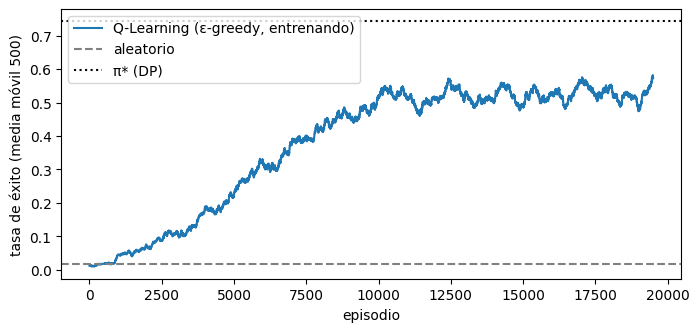

In [6]:
w = 500
media = lambda x: np.convolve(x, np.ones(w) / w, mode="valid")
plt.figure(figsize=(8, 3.5))
plt.plot(media(ret_ql), label="Q-Learning (ε-greedy, entrenando)")
plt.axhline(ret_azar.mean(), color="gray", ls="--", label="aleatorio")
plt.axhline(simular_politica(env, pi_star, semilla=SEED), color="k", ls=":", label="π* (DP)")
plt.xlabel("episodio"); plt.ylabel(f"tasa de éxito (media móvil {w})"); plt.legend(); plt.show()

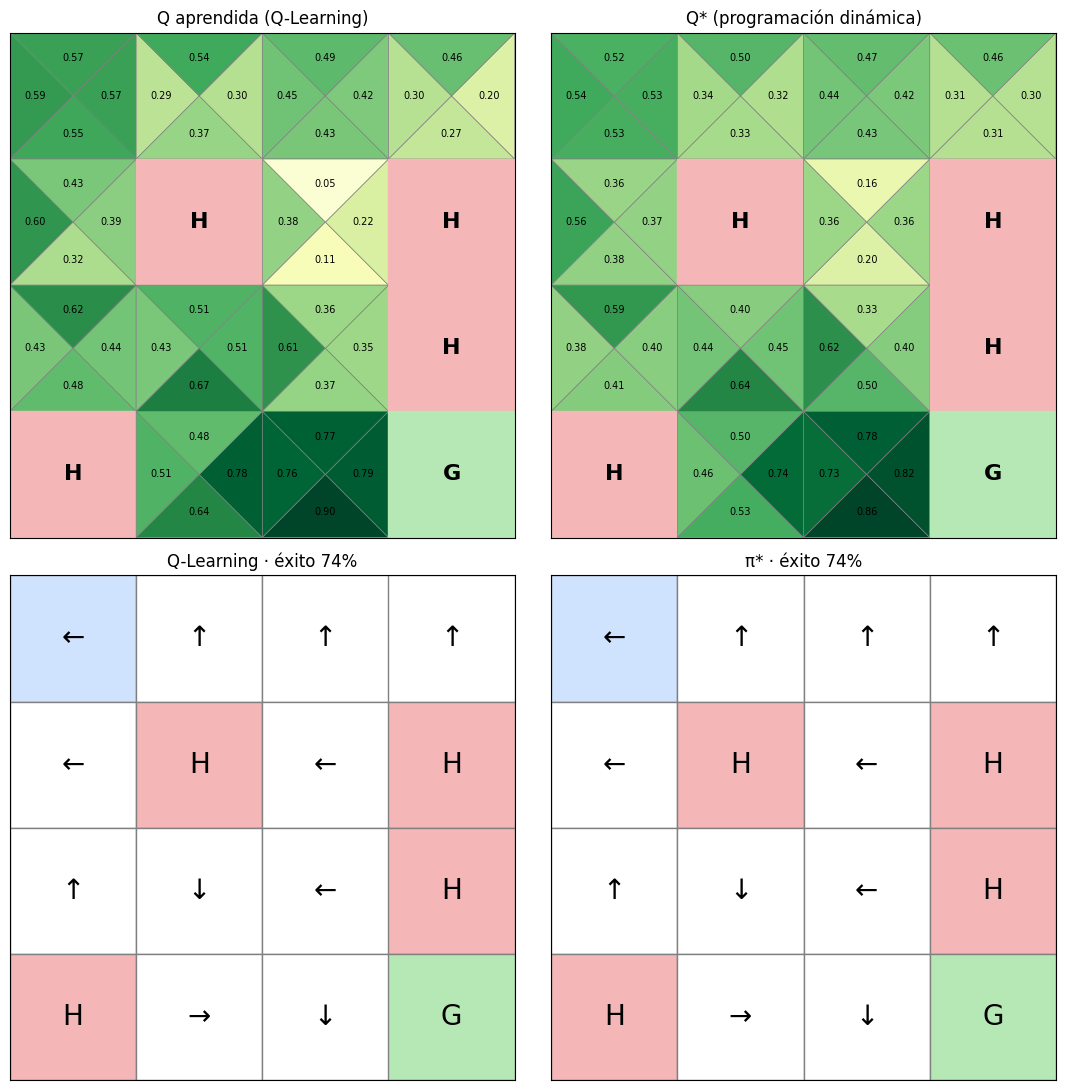

In [7]:
vmax = Q_star[[s for s in range(nS) if s not in estados_terminales(env)]].max()
fig, ax = plt.subplots(2, 2, figsize=(11, 11))
graficar_Q(Q_ql, env, "Q aprendida (Q-Learning)", ax[0, 0], vmax)
graficar_Q(Q_star, env, "Q* (programación dinámica)", ax[0, 1], vmax)
graficar_politica(pi_ql, env, f"Q-Learning · éxito {simular_politica(env, pi_ql, semilla=SEED):.0%}", ax[1, 0])
graficar_politica(pi_star, env, f"π* · éxito {simular_politica(env, pi_star, semilla=SEED):.0%}", ax[1, 1])
plt.tight_layout(); plt.show()

**Lectura:**
- La curva de entrenamiento queda **debajo** de la política final: mientras entrena, el agente sigue explorando con $\varepsilon$.
- Las diferencias con $Q^\star$ están en celdas poco visitadas. Q-Learning converge a $Q^\star$ solo si visita cada $(s,a)$ infinitas veces.
- Q-Learning es **off-policy**: se comporta con $\varepsilon$-greedy pero aprende el valor de la política greedy (el `max`).

**Mi explicación (sección 4)**

La curva empieza igual que el agente aleatorio y va subiendo hasta más o menos 55% de éxito, pero se queda abajo de la línea de pi* porque mientras entrena el agente sigue explorando con epsilon. Ya con la política final, sin explorar, Q-Learning saca 74%, igual que la política de programación dinámica, y las flechas salen iguales en todas las casillas. Los números de Q no son exactamente iguales a Q*, sobre todo en la casilla 6 que casi no se visita, pero eso no cambió las decisiones. Algo curioso es que en la casilla 0 conviene ir a la izquierda: como ahí hay pared, si resbala no pasa nada y es la forma más segura de no acercarse a los hoyos.

## 5. El bug de `terminated`

Si olvidamos quitar el bootstrap al terminar, el valor de los hoyos y la meta se "filtra" hacia atrás.
Con $Q_0=0$ no se nota (las celdas terminales nunca se actualizan y quedan en 0). Con $Q_0=1$ (inicialización optimista) aparece:

In [8]:
Q_ok,  _ = q_learning(env, Q0=1.0)
Q_bug, _ = q_learning(env, Q0=1.0, bug_terminal=True)
no_term = [s for s in range(nS) if s not in estados_terminales(env)]

# El retorno máximo posible en FrozenLake es 1: ningún Q debería pasar de 1
print(f"{'':10s}  max Q(s,a)   Q(6,←)   éxito greedy")
print(f"{'Q*':10s}  {Q_star[no_term].max():10.3f}   {Q_star[6, 0]:6.3f}")
for nombre, Q in [("correcto", Q_ok), ("con bug", Q_bug)]:
    print(f"{nombre:10s}  {Q[no_term].max():10.3f}   {Q[6, 0]:6.3f}   {simular_politica(env, Q.argmax(1), semilla=SEED):11.0%}")

            max Q(s,a)   Q(6,←)   éxito greedy
Q*               0.863    0.358
correcto         0.865    0.120           75%
con bug          1.768    1.084           75%


En la celda 6, ← cae al hoyo 5 con prob. 1/3. Con el bug, el agente toma $Q(\text{hoyo})=1$ como futuro: cree que caer vale $\gamma\cdot 1$ y aparecen valores **mayores a 1**, imposibles.
Aquí la política greedy sale parecida porque el error infla casi todo por igual, pero los valores están corruptos y en otro problema sí cambian el orden de las acciones. Es un bug silencioso: el código corre y "aprende".
En trading, marcar el último bar del histórico como `terminated` enseña que "el mundo se acaba" ahí. El fin de datos es `truncated`.

**Mi explicación (sección 5)**

Se entrenó dos veces empezando con todos los Q en 1, una bien y otra con el bug de no poner el futuro en 0 cuando el episodio termina. La versión correcta da un máximo de 0.865, casi igual que Q* (0.863). La del bug llega a 1.768, que es imposible porque en este juego lo máximo que se puede ganar es 1. En la casilla 6 ir a la izquierda (hacia el hoyo) vale 0.358 en Q*, pero con el bug vale 1.084, o sea que el agente cree que caer en el hoyo está bien. Lo peligroso es que las dos políticas sacan 75% de éxito, entonces si solo ves el resultado final no te das cuenta de que los valores están mal.

## 6. SARSA: on-policy

$$Q(s,a) \leftarrow Q(s,a) + \alpha\big[r + \gamma\,Q(s',\mathbf{a'}) - Q(s,a)\big]$$

Un solo cambio: $\max_{a'}Q(s',a')$ se reemplaza por $Q(s',a')$ de la acción que **realmente** se toma (incluida la exploración).
SARSA aprende el valor de la política $\varepsilon$-greedy, así que descuenta el costo de sus propios errores: es más cauteloso.

In [9]:
# ε fijo en 0.1 para que la diferencia se vea: ambos exploran igual todo el tiempo
Q_q, r_q = q_learning(env, eps=0.1, eps_min=0.1, metodo="q")
Q_s, r_s = q_learning(env, eps=0.1, eps_min=0.1, metodo="sarsa")

print(f"{'':12s}  éxito entrenando (ε=0.1)   éxito greedy final   V(0) estimado")
for nombre, Q, r in [("Q-Learning", Q_q, r_q), ("SARSA", Q_s, r_s)]:
    print(f"{nombre:12s}  {r[-5000:].mean():22.1%}   {simular_politica(env, Q.argmax(1), semilla=SEED):18.1%}   {Q[0].max():.3f}")
print(f"{'V*(0) de DP':12s}  {'':22s}   {'':18s}   {Q_star[0].max():.3f}")

              éxito entrenando (ε=0.1)   éxito greedy final   V(0) estimado
Q-Learning                     39.6%                74.2%   0.558
SARSA                          37.1%                63.5%   0.277
V*(0) de DP                                                 0.542


SARSA estima un $V(0)$ menor: incluye el riesgo de que, 10% de las veces, haga algo al azar.
**Regla práctica:** si exploras en simulador y solo despliegas la política final, Q-Learning. Si aprendes operando dinero real, la cautela de SARSA vale P&L.

**Mi explicación (sección 6)**

Se compararon Q-Learning y SARSA con epsilon fijo en 0.1. SARSA estima V(0) = 0.277, mucho más bajo que Q-Learning (0.558) y que el valor real de DP (0.542), porque SARSA toma en cuenta que el 10% de las veces va a hacer algo al azar y eso le cuesta. Q-Learning aprende el valor como si después fuera a jugar perfecto, por eso queda cerca de V*. Al quitar la exploración, la política de Q-Learning saca 74.2% y la de SARSA 63.5%, porque SARSA aprendió una política pensada para un agente que se equivoca. Mientras entrenan los dos quedan parecidos (39.6% contra 37.1%).

## 7. Efecto de $\alpha$ y $\gamma$

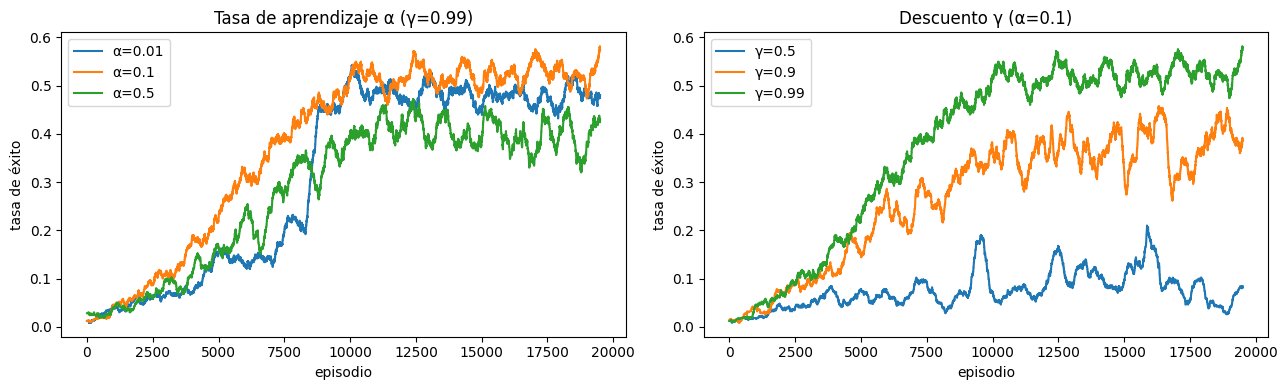

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for alpha in [0.01, 0.1, 0.5]:
    _, r = q_learning(env, alpha=alpha)
    ax[0].plot(media(r), label=f"α={alpha}")
ax[0].set_title("Tasa de aprendizaje α (γ=0.99)")

for g in [0.5, 0.9, 0.99]:
    _, r = q_learning(env, gamma=g)
    ax[1].plot(media(r), label=f"γ={g}")
ax[1].set_title("Descuento γ (α=0.1)")
for a_ in ax:
    a_.set_xlabel("episodio"); a_.set_ylabel("tasa de éxito"); a_.legend()
plt.tight_layout(); plt.show()

- $\alpha$ chico: estable pero lento. $\alpha$ grande: rápido pero ruidoso (el hielo hace que una sola muestra engañe mucho).
- $\gamma$ chico: el agente es miope y no "ve" la meta desde lejos (igual que en la S17).

**Mi explicación (sección 7)**

En la gráfica de alpha, con 0.1 aprende más rápido y llega más alto. Con 0.01 va lento al principio y después alcanza casi lo mismo, y con 0.5 la curva es más ruidosa y se queda más abajo (alrededor de 40%) porque un solo resultado de suerte o mala suerte por el hielo mueve mucho los valores. En gamma, con 0.5 casi no aprende (se queda abajo de 10%) porque la recompensa de la meta se descuenta tanto que desde lejos casi no se ve. Con 0.9 llega a cerca de 40% y con 0.99 a más de 50%.

## 8. Un entorno de trading propio

Heredamos de `gym.Env` y cumplimos el contrato. Usamos precios sintéticos (semilla 42) para no depender de descargas.

- Acciones: `0` corto, `1` fuera, `2` largo  →  posición $\in\{-1,0,+1\}$
- Observación: los últimos `window` rendimientos (hasta $t-1$) y la posición actual
- Recompensa: $\text{pnl}_t = \text{pos}_t\,(p_{t+1}-p_t) - c\,|\Delta\text{pos}|\,p_t$, escalada por el capital inicial
- `terminated` = ruina (equity < 50%); `truncated` = se acabaron los datos

In [11]:
from gymnasium import spaces

class TradingEnv(gym.Env):
    def __init__(self, df, window=30, cost=0.001, init_cash=100_000):
        super().__init__()
        self.df, self.window, self.cost, self.init_cash = df, window, cost, init_cash
        self.action_space = spaces.Discrete(3)                       # 0 corto, 1 fuera, 2 largo
        self.observation_space = spaces.Box(-np.inf, np.inf, shape=(window + 1,), dtype=np.float32)

    def _obs(self):
        rets = self.df["ret"].iloc[self.t - self.window : self.t].values   # solo hasta t-1
        return np.append(rets, self.position).astype(np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.t, self.position, self.equity = self.window, 0, self.init_cash
        return self._obs(), {}

    def step(self, action):
        target = int(action) - 1                                      # {0,1,2} -> {-1,0,+1}
        p_now, p_next = self.df["close"].iloc[self.t], self.df["close"].iloc[self.t + 1]
        costo = self.cost * abs(target - self.position) * p_now       # costo sobre el CAMBIO de posición
        pnl = target * (p_next - p_now) - costo
        self.equity += pnl
        self.position = target
        self.t += 1
        terminated = bool(self.equity <= 0.5 * self.init_cash)        # ruina
        truncated = bool(self.t >= len(self.df) - 1)                  # fin de datos
        return self._obs(), pnl / self.init_cash, terminated, truncated, {"equity": self.equity}

rng = np.random.default_rng(SEED)
precio = 100 * np.exp(np.cumsum(rng.normal(0.0003, 0.01, 500)))
df = pd.DataFrame({"close": precio})
df["ret"] = df["close"].pct_change().fillna(0.0)

**Primero se valida el entorno, después el agente.** Dos pruebas:
1. `check_env` de Gymnasium revisa que se cumpla el contrato (tipos, espacios, semillas).
2. Buy-and-hold debe ganar exactamente lo que se movió el activo (menos el costo de entrar). Si no, el entorno está mal y ningún agente lo arregla.

In [12]:
from gymnasium.utils.env_checker import check_env

import warnings
warnings.filterwarnings("ignore", message=".*infinity.*")     # Box(-inf, inf) es intencional

env_tr = TradingEnv(df)
check_env(env_tr, skip_render_check=True)
print("check_env: OK")

def correr(env, politica, semilla=SEED):
    obs, _ = env.reset(seed=semilla)
    terminado = truncado = False
    while not (terminado or truncado):
        obs, r, terminado, truncado, info = env.step(politica(obs))
    return info["equity"], terminado, truncado

env_tr.action_space.seed(SEED)
eq_bh, term, trunc = correr(env_tr, lambda obs: 2)                       # siempre largo
eq_rnd, _, _ = correr(env_tr, lambda obs: env_tr.action_space.sample())  # aleatorio

w0, cost = env_tr.window, env_tr.cost
esperado = env_tr.init_cash + (precio[-1] - precio[w0]) - cost * precio[w0]
print(f"buy-and-hold: equity final {eq_bh:,.4f}  esperado {esperado:,.4f}  ¿iguales? {np.isclose(eq_bh, esperado)}")
print(f"  terminó por: terminated={term}, truncated={trunc}")
print(f"aleatorio:    equity final {eq_rnd:,.4f}   (paga costo en cada cambio de posición)")

check_env: OK
buy-and-hold: equity final 100,005.0586  esperado 100,005.0586  ¿iguales? True
  terminó por: terminated=False, truncated=True
aleatorio:    equity final 99,956.8923   (paga costo en cada cambio de posición)


**Para verificar en tu propio entorno:** la observación en $t$ usa solo barras hasta $t-1$; la recompensa usa $p_{t+1}-p_t$ con la posición ya tomada; el costo se cobra sobre el cambio de posición, no sobre la posición.

**Mi explicación (sección 8)**

Se creó un entorno de trading propio con precios simulados. Primero check_env revisó que cumpla las reglas de Gymnasium y pasó sin problema. Luego se probó comprar y mantener: el equity final fue 100,005.0586, exactamente lo que se esperaba (lo que subió el precio menos el costo de entrar), y terminó por truncated porque se acabaron los datos, no por ruina. El agente aleatorio terminó con 99,956.89, o sea que perdió porque paga comisión cada vez que cambia de posición. Con esto sabemos que el entorno calcula bien antes de meterle un agente.

## 9. Por qué la tabla no escala a trading

FrozenLake: 16 estados × 4 acciones = 64 números. Un estado de mercado modesto, discretizado, explota:

In [13]:
def tamano_tabla(n_features, bins, n_posiciones=3, n_acciones=3):
    return bins ** n_features * n_posiciones * n_acciones

for nf, b in [(2, 10), (6, 8), (8, 10)]:
    n = tamano_tabla(nf, b)
    print(f"{nf} features × {b:2d} bins -> {n:>15,} entradas  ·  10 visitas c/u = {10*n/252:>14,.0f} años de barras diarias")

2 features × 10 bins ->             900 entradas  ·  10 visitas c/u =             36 años de barras diarias
6 features ×  8 bins ->       2,359,296 entradas  ·  10 visitas c/u =         93,623 años de barras diarias
8 features × 10 bins ->     900,000,000 entradas  ·  10 visitas c/u =     35,714,286 años de barras diarias


**Mi explicación (sección 9)**

En FrozenLake la tabla tiene 64 números, pero en trading si discretizamos varias variables crece muy rápido. Con 2 variables y 10 bins son 900 entradas, que ya serían 36 años de datos diarios para visitar cada una 10 veces. Con 6 variables y 8 bins son más de 2.3 millones de entradas y harían falta como 93 mil años de datos, y con 8 variables son 900 millones. O sea que la tabla no sirve para un problema real de trading y se necesita algo que generalice, como una red neuronal.

**Dos fallas:** (1) memoria: la tabla no cabe; (2) generalización: dos estados de mercado casi iguales son celdas independientes,
lo que aprende en una no le enseña nada de la otra. La solución es una función $Q_\theta(s,a)$ que interpole: la red de la S19 (DQN).

**Para llevar**
1. Model-free = cambiar la esperanza de Bellman por muestras $(s,a,r,s')$.
2. Q-Learning usa $\max$ → off-policy → aprende $Q^\star$ aunque explore.
3. SARSA usa la acción tomada → on-policy → cauteloso.
4. `terminated` sin bootstrap; `truncated` con bootstrap.
5. Valida el entorno (aleatorio y buy-and-hold) antes de entrenar.

**Ejercicios:** (a) repite la sección 4 con `is_slippery=False`; (b) agrega una recompensa de $-0.01$ por paso con un `gym.RewardWrapper` y observa la política;
(c) discretiza dos features de `TradingEnv` (último rendimiento y posición) y corre Q-Learning tabular: documenta dónde se rompe.

# Parte 2. Preguntas de investigación

### 1. Monte Carlo vs TD

Para una transición que sale de $S_t$, el target de Monte Carlo es el retorno completo hasta que termina el episodio:

$$G_t = R_{t+1} + \gamma R_{t+2} + \gamma^2 R_{t+3} + \dots + \gamma^{T-t-1} R_T$$

y el de TD(0) solo usa el siguiente paso y una estimación de lo que falta:

$$R_{t+1} + \gamma V(S_{t+1})$$

En el notebook, la línea `r + gamma * futuro` de `q_learning` es justo un target TD, con `futuro` igual al max de Q en el siguiente estado.

Sesgo: Monte Carlo no tiene sesgo porque usa lo que de verdad pasó, mientras que TD sí tiene sesgo porque usa $V(S_{t+1})$, que al principio puede estar mal. Varianza: Monte Carlo tiene más varianza porque suma muchas recompensas al azar (en FrozenLake cada paso puede resbalar), y TD tiene menos porque depende de una sola transición.

Bootstrapping es actualizar una estimación usando otra estimación, como hace TD al usar $V(S_{t+1})$ dentro de su propio target. TD($\lambda$) mezcla los targets de 1, 2, 3, ... pasos con pesos $(1-\lambda)\lambda^{n-1}$. Con $\lambda=0$ queda solo el de un paso, o sea TD(0), y con $\lambda=1$ queda el retorno completo, o sea Monte Carlo (Sutton y Barto, 2018, cap. 6 y 12).

### 2. Convergencia

Robbins y Monro (1951) dicen que para que un método de aproximación estocástica converja, los pasos $\alpha_t$ tienen que cumplir:

$$\sum_{t=1}^{\infty} \alpha_t = \infty \qquad \text{y} \qquad \sum_{t=1}^{\infty} \alpha_t^2 < \infty$$

La primera es para que los pasos sean lo bastante grandes para llegar a cualquier valor, y la segunda para que al final sean tan chicos que el ruido deje de mover la estimación (Sutton y Barto, 2018, sec. 2.7).

El $\alpha$ fijo de 0.1 del notebook cumple la primera, porque $0.1+0.1+\dots$ diverge, pero no la segunda, porque $0.01+0.01+\dots$ también diverge. Entonces no hay garantía de convergencia exacta: Q se queda oscilando alrededor de $Q^\star$. Eso se ve en la sección 4, donde los valores aprendidos no son exactamente $Q^\star$, y en la sección 7, donde con $\alpha=0.5$ las curvas son más ruidosas. En la práctica a veces se prefiere un $\alpha$ fijo cuando el problema cambia con el tiempo, como en mercados.

La otra condición es que todos los pares $(s,a)$ se visiten infinitas veces (Watkins y Dayan, 1992). Por eso el notebook deja $\varepsilon$ en un mínimo de 0.05 y no en 0. Aun así la casilla 6 se visita poco y ahí es donde Q más se aleja de $Q^\star$.

### 3. On-policy vs off-policy

Lo único que cambia es el futuro del target. Q-Learning usa $\max_{a'} Q(s',a')$ y SARSA usa $Q(s',a')$ con $a'$ la acción que de verdad va a tomar con $\varepsilon$-greedy. Eso significa que Q-Learning aprende el valor de la política greedy aunque se esté comportando con exploración (off-policy), y SARSA aprende el valor de la misma política $\varepsilon$-greedy que está usando (on-policy).

En el ejemplo Cliff Walking (Sutton y Barto, 2018, ej. 6.6) hay que cruzar una cuadrícula junto a un acantilado, cada paso vale -1 y caer vale -100. Con $\varepsilon=0.1$, Q-Learning aprende el camino óptimo pegado al borde, pero mientras entrena se cae seguido por la exploración. SARSA aprende un camino más alejado del borde, más largo pero más seguro, y por eso le va mejor durante el entrenamiento.

En la sección 6 del notebook se ve la misma idea: SARSA estima $V(0)=0.277$ contra 0.558 de Q-Learning porque cuenta el costo de sus propios errores al explorar, y su política final es más conservadora (63.5% contra 74.2% sin exploración). La diferencia con Cliff Walking es que aquí durante el entrenamiento los dos quedaron parecidos (37.1% contra 39.6%), probablemente porque en FrozenLake el riesgo viene más del hielo que de la exploración.

### 4. Expected SARSA y Double Q-Learning

Expected SARSA en lugar de usar una sola acción $a'$ usa el promedio de todas pesado por la política:

$$r + \gamma \sum_{a'} \pi(a'|s')\, Q(s',a')$$

Así se quita la variación que mete elegir $a'$ al azar. Si la política es greedy, queda igual a Q-Learning (Sutton y Barto, 2018, sec. 6.6).

Double Q-Learning (van Hasselt, 2010) resuelve el sesgo de maximización. Cuando los Q tienen ruido, tomar el máximo de varias estimaciones da en promedio un valor más alto que el verdadero, porque el max tiende a escoger la que tuvo ruido a favor:

$$E\big[\max_a \hat Q(s,a)\big] \ \geq\ \max_a E\big[\hat Q(s,a)\big]$$

La solución es tener dos tablas, una para elegir la acción y otra para evaluarla:

$$Q_A(s,a) \leftarrow Q_A(s,a) + \alpha\Big[r + \gamma\, Q_B\big(s', \arg\max_{a'} Q_A(s',a')\big) - Q_A(s,a)\Big]$$

y en cada paso se escoge al azar cuál tabla actualizar.

En el notebook se nota un poco: en la sección 4 varios valores aprendidos quedan arriba de $Q^\star$, por ejemplo en la casilla 14 hacia abajo 0.90 contra 0.86, y en la casilla 0 hacia la izquierda 0.59 contra 0.54.

En trading importa mucho porque los rendimientos tienen muchísimo ruido y poca señal. Si el agente toma el max sobre estimaciones ruidosas va a creer que alguna acción es rentable solo por suerte en los datos, sobreestima la ganancia esperada y termina operando de más (y pagando comisiones). Es el mismo problema de elegir la mejor estrategia de muchos backtests.

### 5. terminated vs truncated

Antes, `step` regresaba una sola bandera `done` que mezclaba dos cosas distintas: que la tarea terminó (caer en un hoyo, quebrar) o que se acabó el tiempo. Desde Gym 0.26 se separó en `terminated` y `truncated` (Towers et al., 2024; documentación de Gymnasium, "Handling Time Limits"), porque para aprender no es lo mismo. Si terminó la tarea, el futuro vale 0 y no se hace bootstrap. Si se cortó por tiempo, el futuro sí existe y se debe usar $\gamma\max Q(s',a')$.

Si en trading marcamos el último bar de cada episodio como terminated, el agente aprende que después de ese bar ya no hay nada, como si el mercado se acabara. Los valores cerca del final de los datos quedan subestimados y el agente aprende algo que depende de cuánto falta para que se acaben los datos, que ni siquiera está en su observación. Eso le enseña cosas falsas, por ejemplo que no vale la pena tener posición al final.

La sección 5 del notebook muestra qué tan silencioso es este tipo de error (ahí es el caso contrario, hacer bootstrap cuando sí terminó): con el bug los valores llegan a 1.768 cuando el máximo posible es 1, pero la política sigue sacando 75% de éxito, igual que la correcta. El código corre y parece que aprende, pero los valores están mal. Por eso en `TradingEnv` el fin de datos se marca como truncated, y en la sección 8 buy-and-hold termina con truncated=True.

### 6. Escalabilidad

Con 6 variables de 8 bins, 3 posiciones y 3 acciones:

$$8^6 \times 3 \times 3 = 262{,}144 \times 9 = 2{,}359{,}296 \text{ entradas}$$

Para visitar cada una 10 veces:

$$10 \times 2{,}359{,}296 = 23{,}592{,}960 \text{ bars}$$

Con barras diarias (252 al año) eso es:

$$\frac{23{,}592{,}960}{252} \approx 93{,}623 \text{ años}$$

que coincide con la tabla de la sección 9. Y eso suponiendo que los datos visitan todas las celdas igual, cuando en realidad muchas combinaciones casi nunca pasan. Incluso con barras de un minuto serían unos 240 años.

Además de la memoria, la tabla no generaliza porque cada celda es independiente. Si dos estados del mercado son casi iguales pero caen en bins distintos, lo que aprendió en uno no le dice nada del otro. La tabla no tiene idea de que un rendimiento de 0.9% y uno de 1.1% se parecen. Por eso se necesita una función $Q_\theta(s,a)$, como una red neuronal, que comparta lo aprendido entre estados parecidos (Sutton y Barto, 2018, cap. 9). Eso es DQN, el tema de la S19.

# Parte 3. Ejercicios en código

### (a) Sección 4 con is_slippery=False

                  éxito greedy   éxito entrenando (últimos 5000)   episodio en que llega a 50%


resbaloso                 74%                             52.5%   10334
sin resbalar             100%                             95.2%   3113


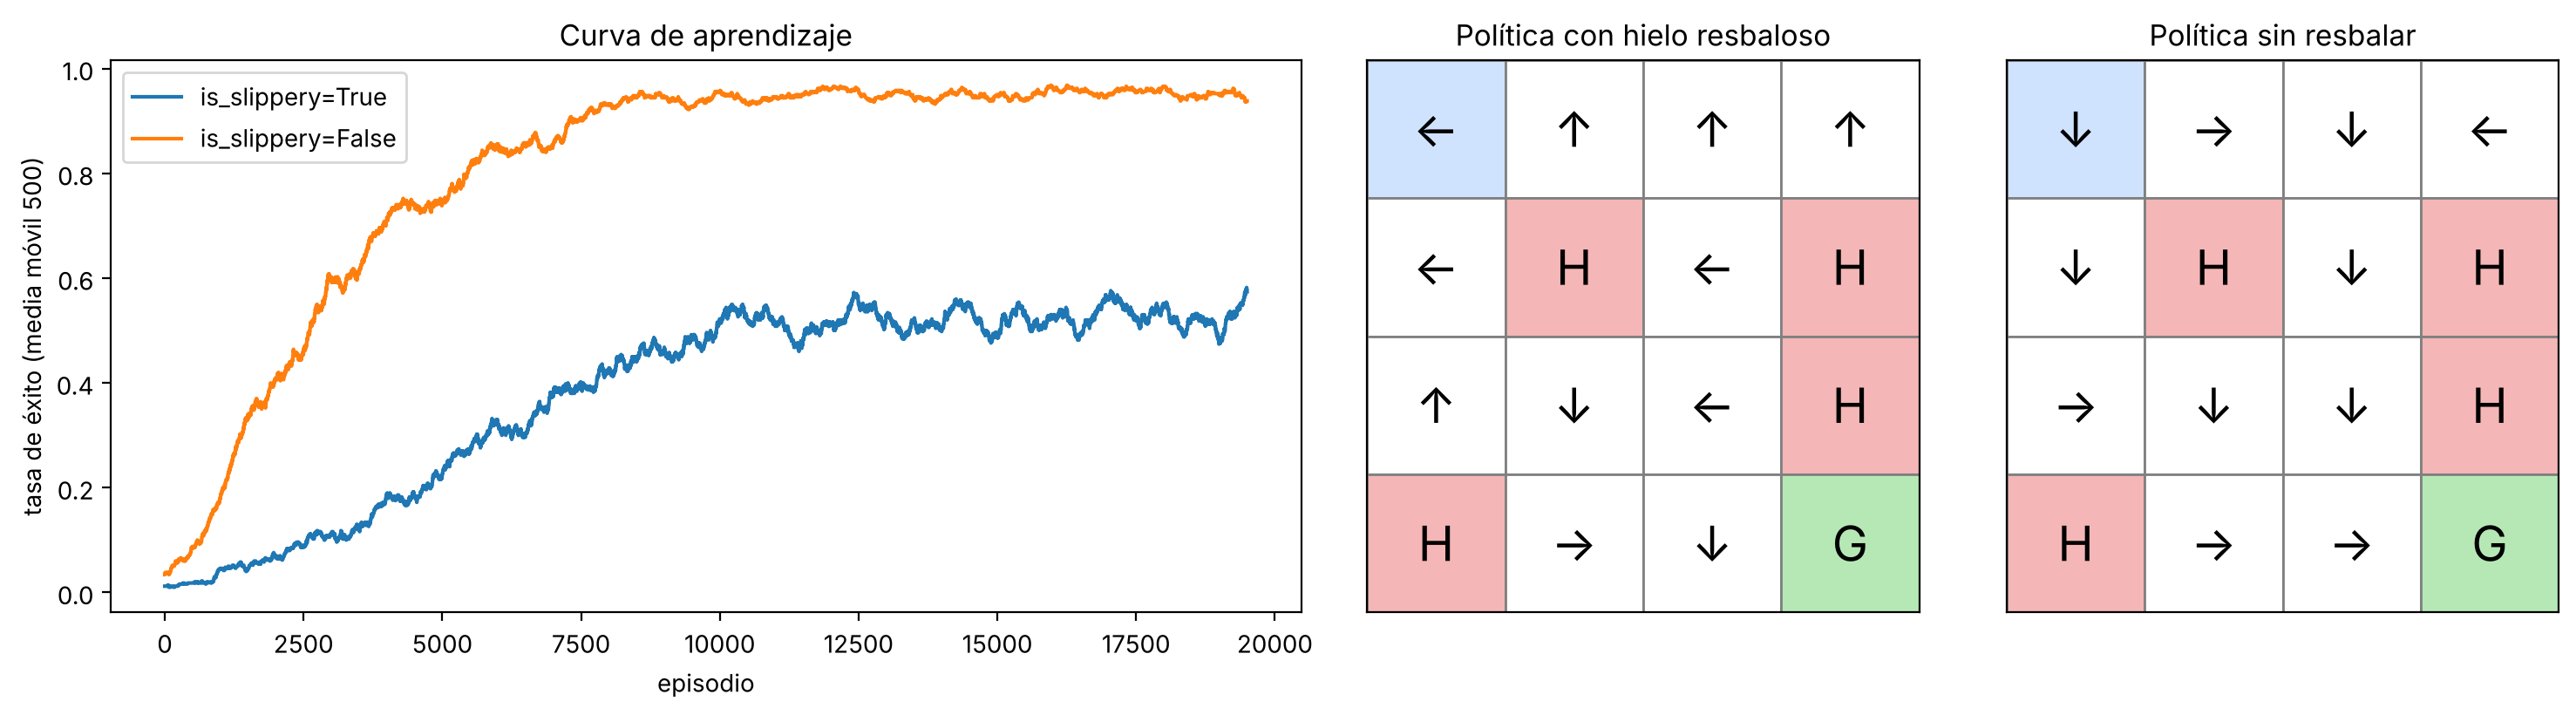

In [14]:
env_det = gym.make("FrozenLake-v1", is_slippery=False)
Q_det, ret_det = q_learning(env_det, gamma=gamma)
pi_det = Q_det.argmax(axis=1)

def primer_episodio(ret, nivel=0.5):
    # primer episodio en que la media móvil de éxito llega a "nivel"
    m = media(ret)
    idx = np.where(m >= nivel)[0]
    return int(idx[0] + w) if len(idx) else None

print(f"{'':16s}  éxito greedy   éxito entrenando (últimos 5000)   episodio en que llega a 50%")
for nombre, e, pi, r in [("resbaloso", env, pi_ql, ret_ql), ("sin resbalar", env_det, pi_det, ret_det)]:
    print(f"{nombre:16s}  {simular_politica(e, pi, semilla=SEED):11.0%}   {r[-5000:].mean():31.1%}   {primer_episodio(r)}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [2, 1, 1]})
ax[0].plot(media(ret_ql), label="is_slippery=True")
ax[0].plot(media(ret_det), label="is_slippery=False")
ax[0].set_xlabel("episodio"); ax[0].set_ylabel(f"tasa de éxito (media móvil {w})")
ax[0].set_title("Curva de aprendizaje"); ax[0].legend()
graficar_politica(pi_ql, env, "Política con hielo resbaloso", ax[1])
graficar_politica(pi_det, env_det, "Política sin resbalar", ax[2])
plt.tight_layout(); plt.show()

**Interpretación**

Sin hielo resbaloso el problema se vuelve determinista y la política greedy llega a la meta el 100% de las veces, contra 74% con hielo. También aprende mucho más rápido: la media móvil pasa de 50% de éxito en el episodio 3,113, mientras que con hielo tarda hasta el 10,334. Durante el entrenamiento llega a 95% y no a 100% porque todavía explora con epsilon de 0.05. La política también cambia: sin resbalar va directo por el camino más corto (abajo, abajo, derecha, abajo, derecha, derecha), mientras que con hielo hace movimientos raros como ir a la izquierda en la casilla 0, que sirven para no arriesgarse a resbalar a un hoyo. Algunas flechas de la política sin resbalar se ven raras (como en la casilla 3), pero son casillas que la política nunca pisa y por eso no importan.

### (b) RewardWrapper que resta 0.01 en cada paso

                              éxito   pasos promedio


Q-Learning sin castigo        74.2%     44.0


Q-Learning con castigo        74.6%     41.0


pi* sin castigo (DP)          74.2%     44.0


pi* con castigo (DP)          73.5%     40.6
casillas donde cambia la acción (DP): [2]
casillas donde cambia la acción (Q-Learning): [2, 6]


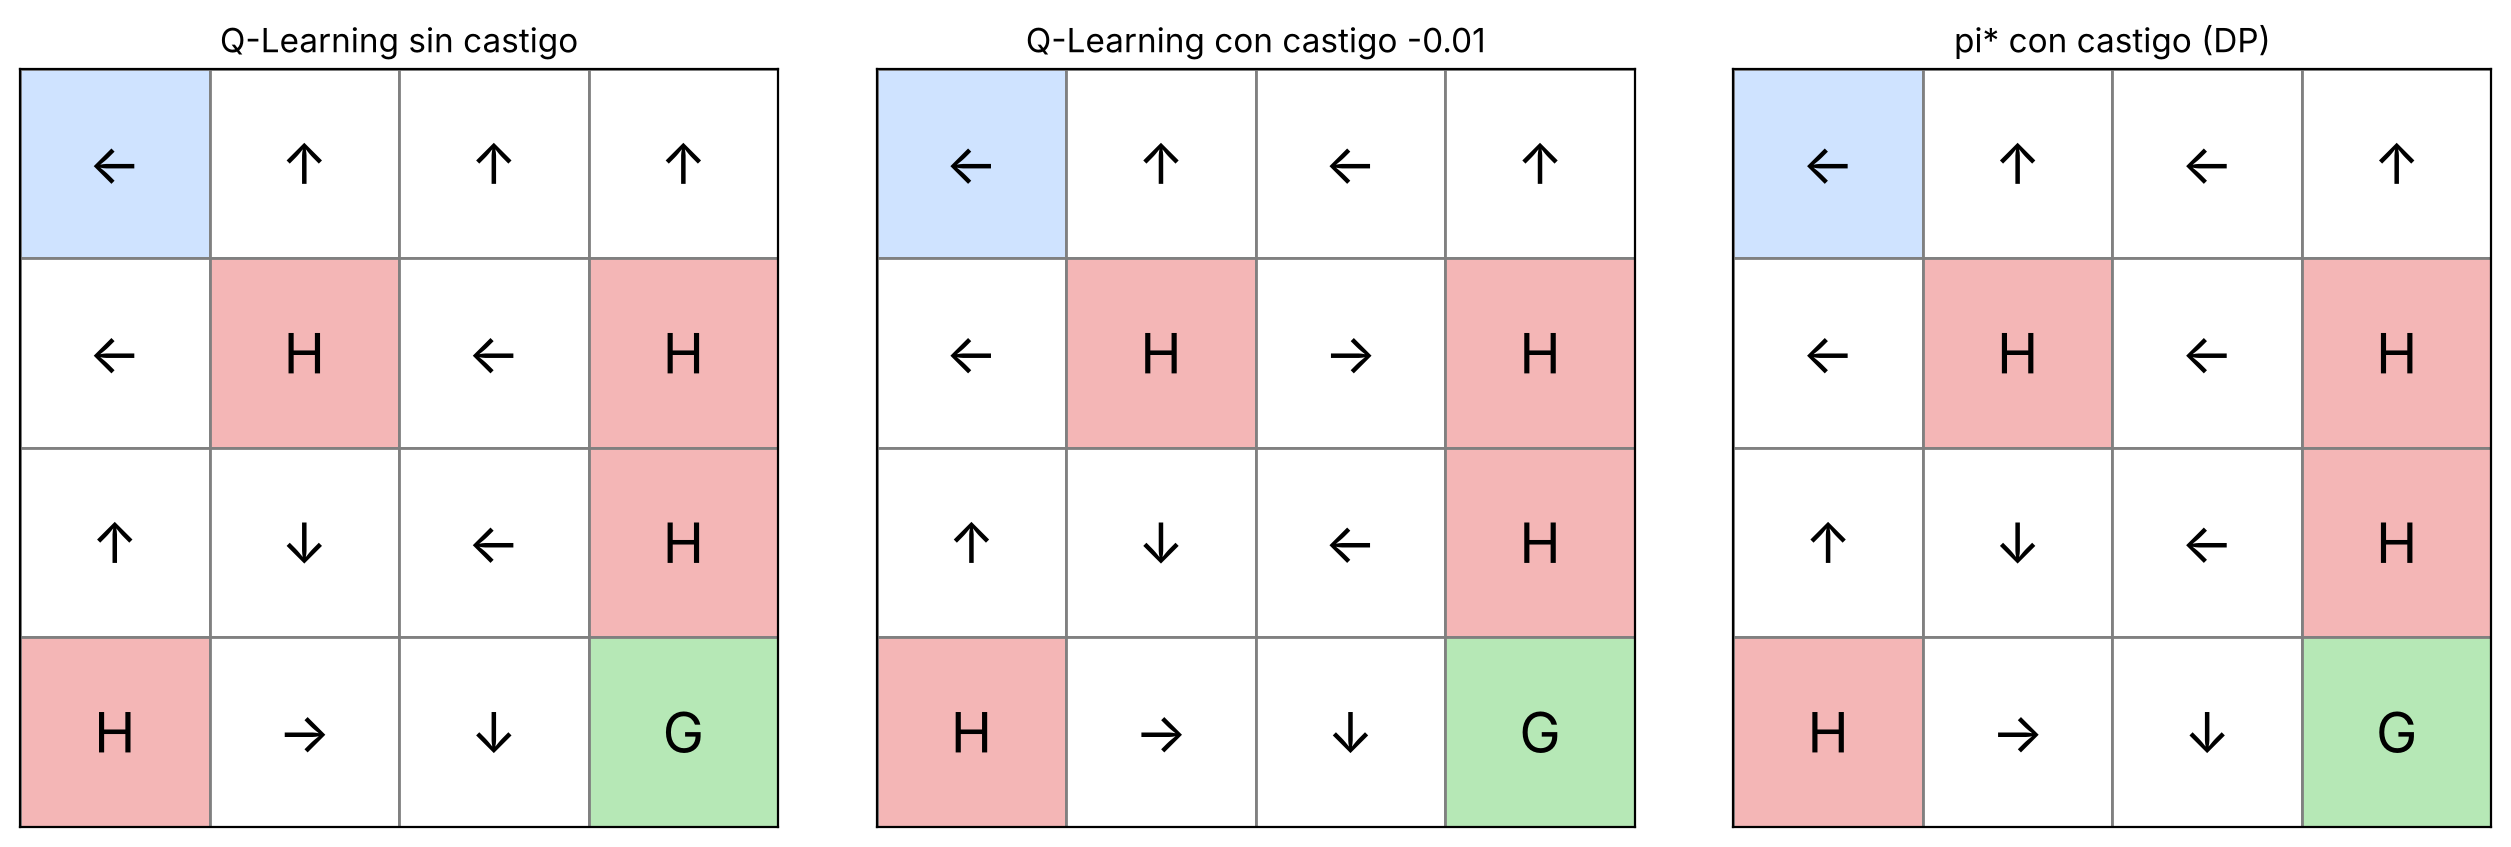

In [15]:
class CastigoPorPaso(gym.RewardWrapper):
    # resta una cantidad fija a la recompensa de cada paso
    def __init__(self, env, castigo=0.01):
        super().__init__(env)
        self.castigo = castigo
    def reward(self, r):
        return r - self.castigo

env_pen = CastigoPorPaso(gym.make("FrozenLake-v1", is_slippery=True))
Q_pen, ret_pen = q_learning(env_pen, gamma=gamma)
pi_pen = Q_pen.argmax(axis=1)

# Referencia con DP: el mismo castigo, pero calculado con el modelo
term = estados_terminales(env)
R_pen = R - 0.01
R_pen[term] = 0.0
V = np.zeros(nS)
for _ in range(1500):
    Q_star_pen = R_pen + gamma * np.einsum("sap,p->sa", P, V)
    Q_star_pen[term] = 0.0
    V = Q_star_pen.max(axis=1)
pi_star_pen = Q_star_pen.argmax(axis=1)

def evaluar(env, politica, n_episodios=2000, semilla=SEED):
    # éxito y número promedio de pasos usando el entorno SIN castigo
    exitos, pasos = 0, []
    env.reset(seed=semilla)
    for _ in range(n_episodios):
        obs, _ = env.reset()
        fin, k = False, 0
        while not fin:
            obs, r, terminado, truncado, _ = env.step(int(politica[obs]))
            fin, k = terminado or truncado, k + 1
        exitos += r
        pasos.append(k)
    return exitos / n_episodios, np.mean(pasos)

no_term = [s for s in range(nS) if s not in term]
print(f"{'':28s}  éxito   pasos promedio")
for nombre, pi in [("Q-Learning sin castigo", pi_ql), ("Q-Learning con castigo", pi_pen),
                   ("pi* sin castigo (DP)", pi_star), ("pi* con castigo (DP)", pi_star_pen)]:
    exito, pasos = evaluar(env, pi)
    print(f"{nombre:28s}  {exito:5.1%}   {pasos:6.1f}")
print("casillas donde cambia la acción (DP):", [s for s in no_term if pi_star[s] != pi_star_pen[s]])
print("casillas donde cambia la acción (Q-Learning):", [s for s in no_term if pi_ql[s] != pi_pen[s]])

fig, ax = plt.subplots(1, 3, figsize=(13, 4.2))
graficar_politica(pi_ql, env, "Q-Learning sin castigo", ax[0])
graficar_politica(pi_pen, env, "Q-Learning con castigo -0.01", ax[1])
graficar_politica(pi_star_pen, env, "pi* con castigo (DP)", ax[2])
plt.tight_layout(); plt.show()

**Interpretación**

Al restar 0.01 por paso la política casi no cambia. Con programación dinámica solo cambia la casilla 2 (de arriba a izquierda), que es tomar un camino un poco más directo. Con Q-Learning cambian la 2 y la 6, pero la 6 es una casilla que casi no se visita, así que puede ser ruido del entrenamiento. El éxito queda prácticamente igual (74.6% contra 74.2%) y los episodios se hacen un poco más cortos (41 pasos en promedio contra 44), que es justo lo que busca el castigo.

Cambia poco porque 0.01 es muy chico comparado con la recompensa de 1 de la meta, y con gamma = 0.99 el agente ya tenía algo de prisa por llegar. Lo que más pesa en FrozenLake es el riesgo de caer en un hoyo, y eso no lo cambia el castigo. Si el castigo fuera mucho más grande, el agente podría preferir terminar rápido aunque sea cayendo en un hoyo, así que hay que tener cuidado con cómo se diseña la recompensa.

### (c) Q-Learning tabular en TradingEnv con dos variables discretizadas

Estado = bin del último rendimiento conocido (barra t-1) y posición actual. Los cortes de los bins salen solo de los datos de entrenamiento, para no usar información del futuro. Se entrena con las primeras 350 barras y se prueba con las demás.

Buy-and-hold: P&L entrenamiento 1.30   P&L prueba 3.23

      estados  entradas Q  % pares con <10 visitas  P&L entrenamiento  P&L prueba
bins                                                                             
2           6          18                     0.00               0.00        0.00
5          15          45                     0.00               0.00        0.00
10         30          90                     0.00               1.46       -6.53
25         75         225                     0.00              36.09       -4.52
50        150         450                     0.22              87.47       -2.16
100       300         900                    14.22             138.56       -5.59


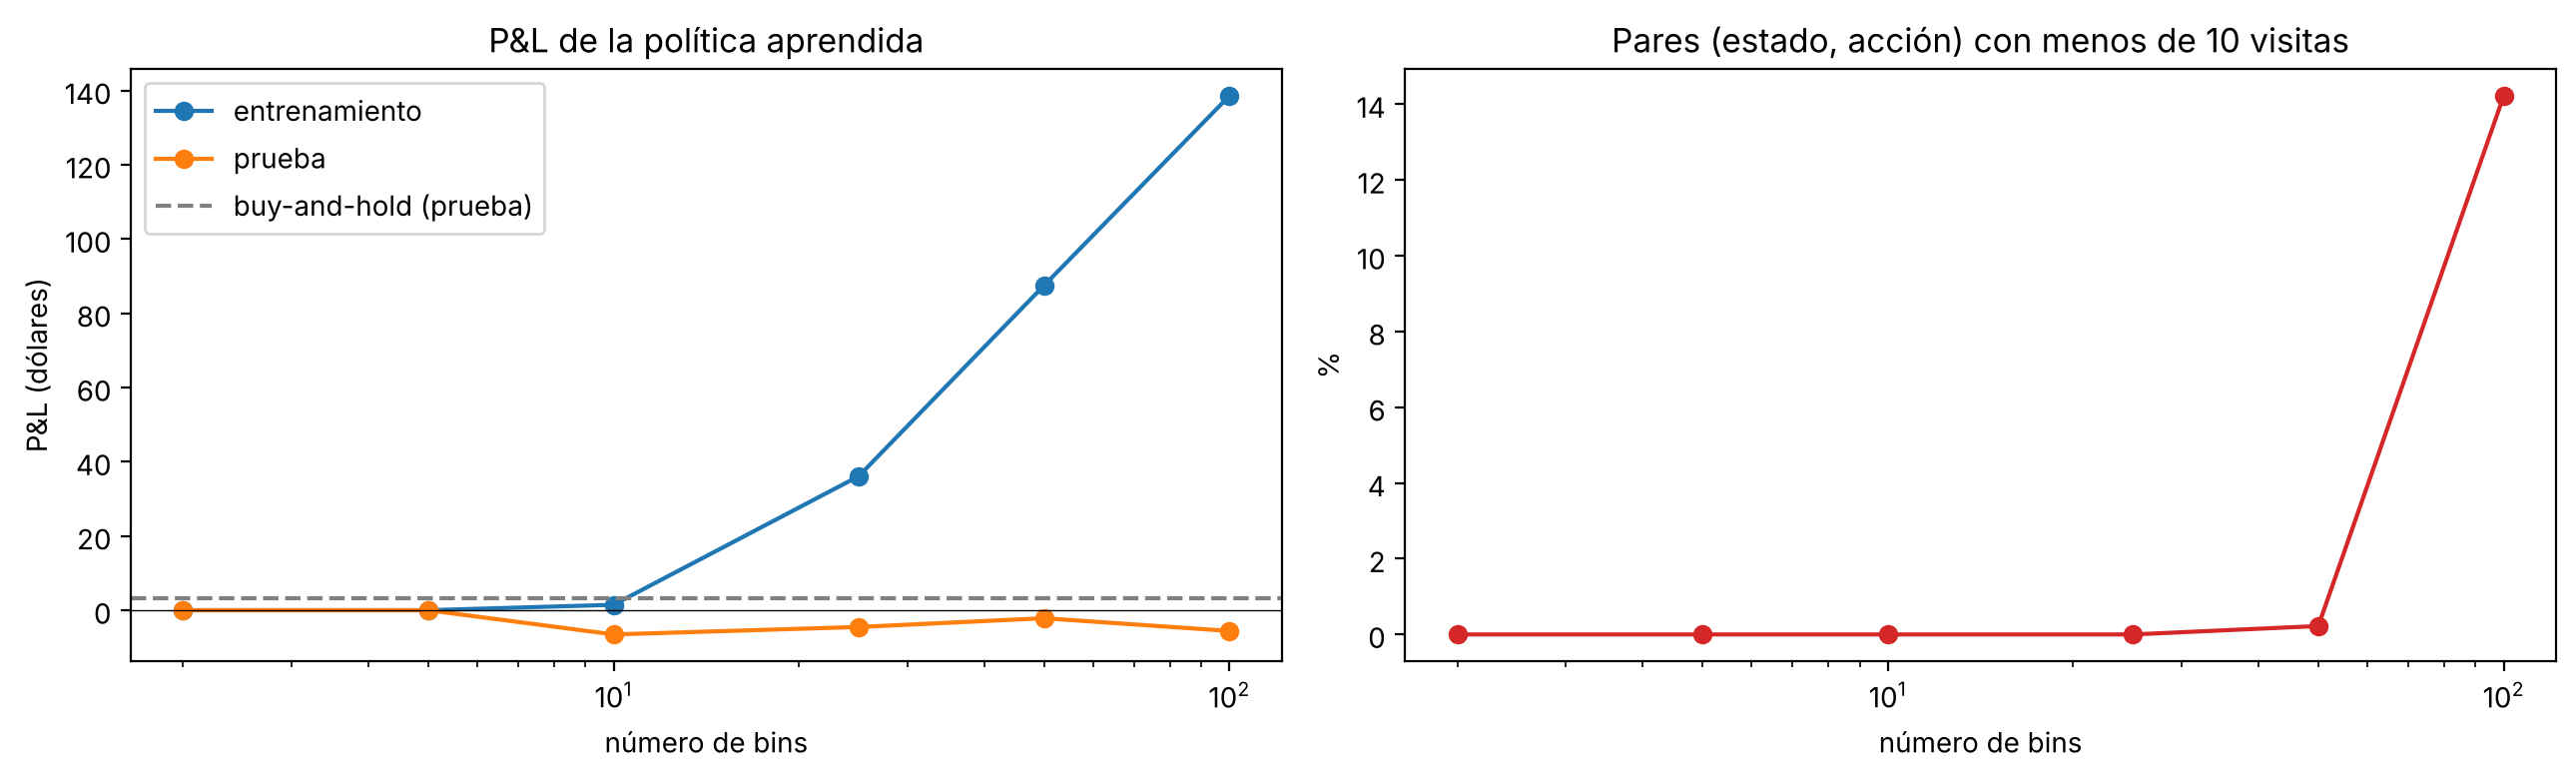

In [16]:
# Separamos los datos: entrenamos con las primeras 350 barras y probamos con las siguientes.
# El periodo de prueba empieza en la barra 320 solo para tener las 30 barras de ventana.
train_df = df.iloc[:350].reset_index(drop=True)
test_df = df.iloc[320:].reset_index(drop=True)

def hacer_discretizador(n_bins):
    # los cortes salen solo de los datos de entrenamiento (nada del futuro)
    cortes = np.quantile(train_df["ret"].iloc[1:], np.linspace(0, 1, n_bins + 1)[1:-1])
    def estado(obs):
        b = int(np.digitize(obs[-2], cortes))      # último rendimiento conocido (barra t-1)
        pos = int(obs[-1]) + 1                       # posición -1, 0, 1 -> 0, 1, 2
        return b * 3 + pos
    return estado

def q_trading(n_bins, episodios=200, alpha=0.1, gamma=0.99, eps=1.0, eps_min=0.05, decay=0.98, semilla=SEED):
    rng = np.random.default_rng(semilla)
    estado = hacer_discretizador(n_bins)
    Q = np.zeros((n_bins * 3, 3))
    visitas = np.zeros((n_bins * 3, 3))
    env_train = TradingEnv(train_df)
    env_train.reset(seed=semilla)
    for ep in range(episodios):
        obs, _ = env_train.reset()
        s, fin = estado(obs), False
        while not fin:
            a = int(rng.integers(3)) if rng.random() < eps else int(Q[s].argmax())
            obs, r, terminado, truncado, _ = env_train.step(a)
            s2 = estado(obs)
            futuro = 0.0 if terminado else Q[s2].max()   # fin de datos = truncated, sí hay bootstrap
            Q[s, a] += alpha * (r + gamma * futuro - Q[s, a])
            visitas[s, a] += 1
            s, fin = s2, terminado or truncado
        eps = max(eps_min, eps * decay)
    return Q, visitas, estado

def pnl_greedy(Q, estado, datos):
    e = TradingEnv(datos)
    obs, _ = e.reset(seed=SEED)
    fin = False
    while not fin:
        obs, r, terminado, truncado, info = e.step(int(Q[estado(obs)].argmax()))
        fin = terminado or truncado
    return info["equity"] - e.init_cash

bh_train = correr(TradingEnv(train_df), lambda obs: 2)[0] - 100_000
bh_test = correr(TradingEnv(test_df), lambda obs: 2)[0] - 100_000

filas = []
for n_bins in [2, 5, 10, 25, 50, 100]:
    Q_tr, visitas, estado = q_trading(n_bins)
    filas.append({"bins": n_bins, "estados": n_bins * 3, "entradas Q": n_bins * 9,
                  "% pares con <10 visitas": 100 * (visitas < 10).mean(),
                  "P&L entrenamiento": pnl_greedy(Q_tr, estado, train_df),
                  "P&L prueba": pnl_greedy(Q_tr, estado, test_df)})
tabla = pd.DataFrame(filas).set_index("bins")
print(f"Buy-and-hold: P&L entrenamiento {bh_train:.2f}   P&L prueba {bh_test:.2f}\n")
print(tabla.round(2).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(tabla.index, tabla["P&L entrenamiento"], "o-", label="entrenamiento")
ax[0].plot(tabla.index, tabla["P&L prueba"], "o-", label="prueba")
ax[0].axhline(bh_test, color="gray", ls="--", label="buy-and-hold (prueba)")
ax[0].axhline(0, color="k", lw=0.5)
ax[0].set_xscale("log"); ax[0].set_xlabel("número de bins"); ax[0].set_ylabel("P&L (dólares)")
ax[0].set_title("P&L de la política aprendida"); ax[0].legend()
ax[1].plot(tabla.index, tabla["% pares con <10 visitas"], "o-", color="C3")
ax[1].set_xscale("log"); ax[1].set_xlabel("número de bins"); ax[1].set_ylabel("%")
ax[1].set_title("Pares (estado, acción) con menos de 10 visitas")
plt.tight_layout(); plt.show()

**Interpretación**

Con 2 y 5 bins el agente aprende a no operar (P&L de 0): como el último rendimiento no le dice nada útil, lo mejor que encuentra es no pagar comisiones. Desde 10 bins empieza a romperse. En entrenamiento el P&L sube mucho conforme agregamos bins (de 1.46 a 138.56 dólares, cuando buy-and-hold solo gana 1.30), pero en prueba siempre pierde dinero (entre -2 y -6.5) y queda abajo de buy-and-hold (3.23). O sea que no aprendió una estrategia, se memorizó el ruido de los datos de entrenamiento.

Esto pasa porque con más bins cada celda tiene menos datos y su Q depende de unos pocos rendimientos que tuvieron suerte. Con 100 bins el 14% de los pares todavía tiene menos de 10 visitas, y eso que el agente repasó los mismos datos 200 veces, que realmente no es información nueva. Además los precios son simulados al azar, entonces no hay ningún patrón que aprender y cualquier ganancia en entrenamiento es sobreajuste.

Con solo una variable ya falla, y si agregamos más la tabla crece como vimos en la sección 9. Lo que falta es poder generalizar entre estados parecidos y no memorizar cada celda por separado, y eso es lo que motiva usar una red neuronal en DQN (S19).

# Referencias

- Robbins, H. y Monro, S. (1951). A stochastic approximation method. The Annals of Mathematical Statistics, 22(3), 400-407.
- Rummery, G. A. y Niranjan, M. (1994). On-line Q-learning using connectionist systems. Technical Report, Cambridge University.
- Sutton, R. S. y Barto, A. G. (2018). Reinforcement Learning: An Introduction (2a ed.). MIT Press. incompleteideas.net
- Towers, M. et al. (2024). Gymnasium: A Standard Interface for Reinforcement Learning Environments. arXiv:2407.17032. Documentación en gymnasium.farama.org
- van Hasselt, H. (2010). Double Q-learning. Advances in Neural Information Processing Systems 23.
- Watkins, C. J. C. H. y Dayan, P. (1992). Q-learning. Machine Learning, 8(3-4), 279-292.